In [1]:
from PIL import Image
import pandas as pd
import numpy as np

from sklearn.model_selection import KFold, GroupKFold, StratifiedGroupKFold
from tqdm.auto import tqdm
tqdm.pandas()


c:\Users\Liuluotu\Anaconda\anaconda3\envs\csiro\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
DATA_ROOT = './data/' 

train_df = pd.read_csv(f'{DATA_ROOT}/train.csv')
train_df.head()

,sample_id,image_path,Sampling_Date,State,Species,Pre_GSHH_NDVI,Height_Ave_cm,target_name,target
0,ID1011485656__Dry_Clover_g,train/ID1011485656.jpg,2015/9/4,Tas,Ryegrass_Clover,0.62,4.6667,Dry_Clover_g,0.0000
1,ID1011485656__Dry_Dead_g,train/ID1011485656.jpg,2015/9/4,Tas,Ryegrass_Clover,0.62,4.6667,Dry_Dead_g,31.9984
2,ID1011485656__Dry_Green_g,train/ID1011485656.jpg,2015/9/4,Tas,Ryegrass_Clover,0.62,4.6667,Dry_Green_g,16.2751
3,ID1011485656__Dry_Total_g,train/ID1011485656.jpg,2015/9/4,Tas,Ryegrass_Clover,0.62,4.6667,Dry_Total_g,48.2735
4,ID1011485656__GDM_g,train/ID1011485656.jpg,2015/9/4,Tas,Ryegrass_Clover,0.62,4.6667,GDM_g,16.2750


In [3]:
train_df[['sample_id_prefix', 'sample_id_suffix']] = train_df.sample_id.str.split('__', expand=True)
train_df


,sample_id,image_path,Sampling_Date,State,Species,Pre_GSHH_NDVI,Height_Ave_cm,target_name,target,sample_id_prefix,sample_id_suffix
0,ID1011485656__Dry_Clover_g,train/ID1011485656.jpg,2015/9/4,Tas,Ryegrass_Clover,0.62,4.6667,Dry_Clover_g,0.0000,ID1011485656,Dry_Clover_g
1,ID1011485656__Dry_Dead_g,train/ID1011485656.jpg,2015/9/4,Tas,Ryegrass_Clover,0.62,4.6667,Dry_Dead_g,31.9984,ID1011485656,Dry_Dead_g
2,ID1011485656__Dry_Green_g,train/ID1011485656.jpg,2015/9/4,Tas,Ryegrass_Clover,0.62,4.6667,Dry_Green_g,16.2751,ID1011485656,Dry_Green_g
3,ID1011485656__Dry_Total_g,train/ID1011485656.jpg,2015/9/4,Tas,Ryegrass_Clover,0.62,4.6667,Dry_Total_g,48.2735,ID1011485656,Dry_Total_g
4,ID1011485656__GDM_g,train/ID1011485656.jpg,2015/9/4,Tas,Ryegrass_Clover,0.62,4.6667,GDM_g,16.2750,ID1011485656,GDM_g
...,...,...,...,...,...,...,...,...,...,...,...
1780,ID983582017__Dry_Clover_g,train/ID983582017.jpg,2015/9/1,WA,Ryegrass,0.64,9.0000,Dry_Clover_g,0.0000,ID983582017,Dry_Clover_g
1781,ID983582017__Dry_Dead_g,train/ID983582017.jpg,2015/9/1,WA,Ryegrass,0.64,9.0000,Dry_Dead_g,0.0000,ID983582017,Dry_Dead_g
1782,ID983582017__Dry_Green_g,train/ID983582017.jpg,2015/9/1,WA,Ryegrass,0.64,9.0000,Dry_Green_g,40.9400,ID983582017,Dry_Green_g
1783,ID983582017__Dry_Total_g,train/ID983582017.jpg,2015/9/1,WA,Ryegrass,0.64,9.0000,Dry_Total_g,40.9400,ID983582017,Dry_Total_g


In [4]:
cols = ['sample_id_prefix', 'image_path', 'Sampling_Date', 'State', 'Species', 'Pre_GSHH_NDVI', 'Height_Ave_cm']
agg_train_df = train_df.groupby(cols).apply(lambda df: df.set_index('target_name').target)
agg_train_df.reset_index(inplace=True)
agg_train_df.columns.name = None

agg_train_df['image'] = agg_train_df.image_path.progress_apply(
    lambda path: Image.open(DATA_ROOT + path).convert('RGB')
)

agg_train_df.head()

print("删除前行数:", agg_train_df.shape[0])
target_index = agg_train_df[agg_train_df['sample_id_prefix'] == 'ID230058600'].index
agg_train_df.drop(target_index, inplace=True)
print("删除后行数:", agg_train_df.shape[0])
# 验证结果
print("删除后是否还存在目标行:", 'ID230058600' in agg_train_df['sample_id_prefix'].values)


C:\Users\Liuluotu\AppData\Local\Temp\ipykernel_61928\3344421434.py:2: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  agg_train_df = train_df.groupby(cols).apply(lambda df: df.set_index('target_name').target)
100%|██████████| 357/357 [00:08<00:00, 42.87it/s]

删除前行数: 357
删除后行数: 356
删除后是否还存在目标行: False


In [5]:
agg_train_df['Sampling_Date'].unique()

array(['2015/9/4', '2015/4/1', '2015/9/1', '2015/5/18', '2015/9/11',
       '2015/9/30', '2015/7/2', '2015/6/30', '2015/5/19', '2015/9/29',
       '2015/1/15', '2015/6/26', '2015/11/9', '2015/2/24', '2015/8/19',
       '2015/6/29', '2015/5/7', '2015/8/14', '2015/8/21', '2015/8/18',
       '2015/7/1', '2015/11/10', '2015/10/13', '2015/10/6', '2015/2/25',
       '2015/7/8', '2015/10/14', '2015/9/3'], dtype=object)

States: ['NSW', 'Tas', 'Vic', 'WA']  (n_states = 4 )


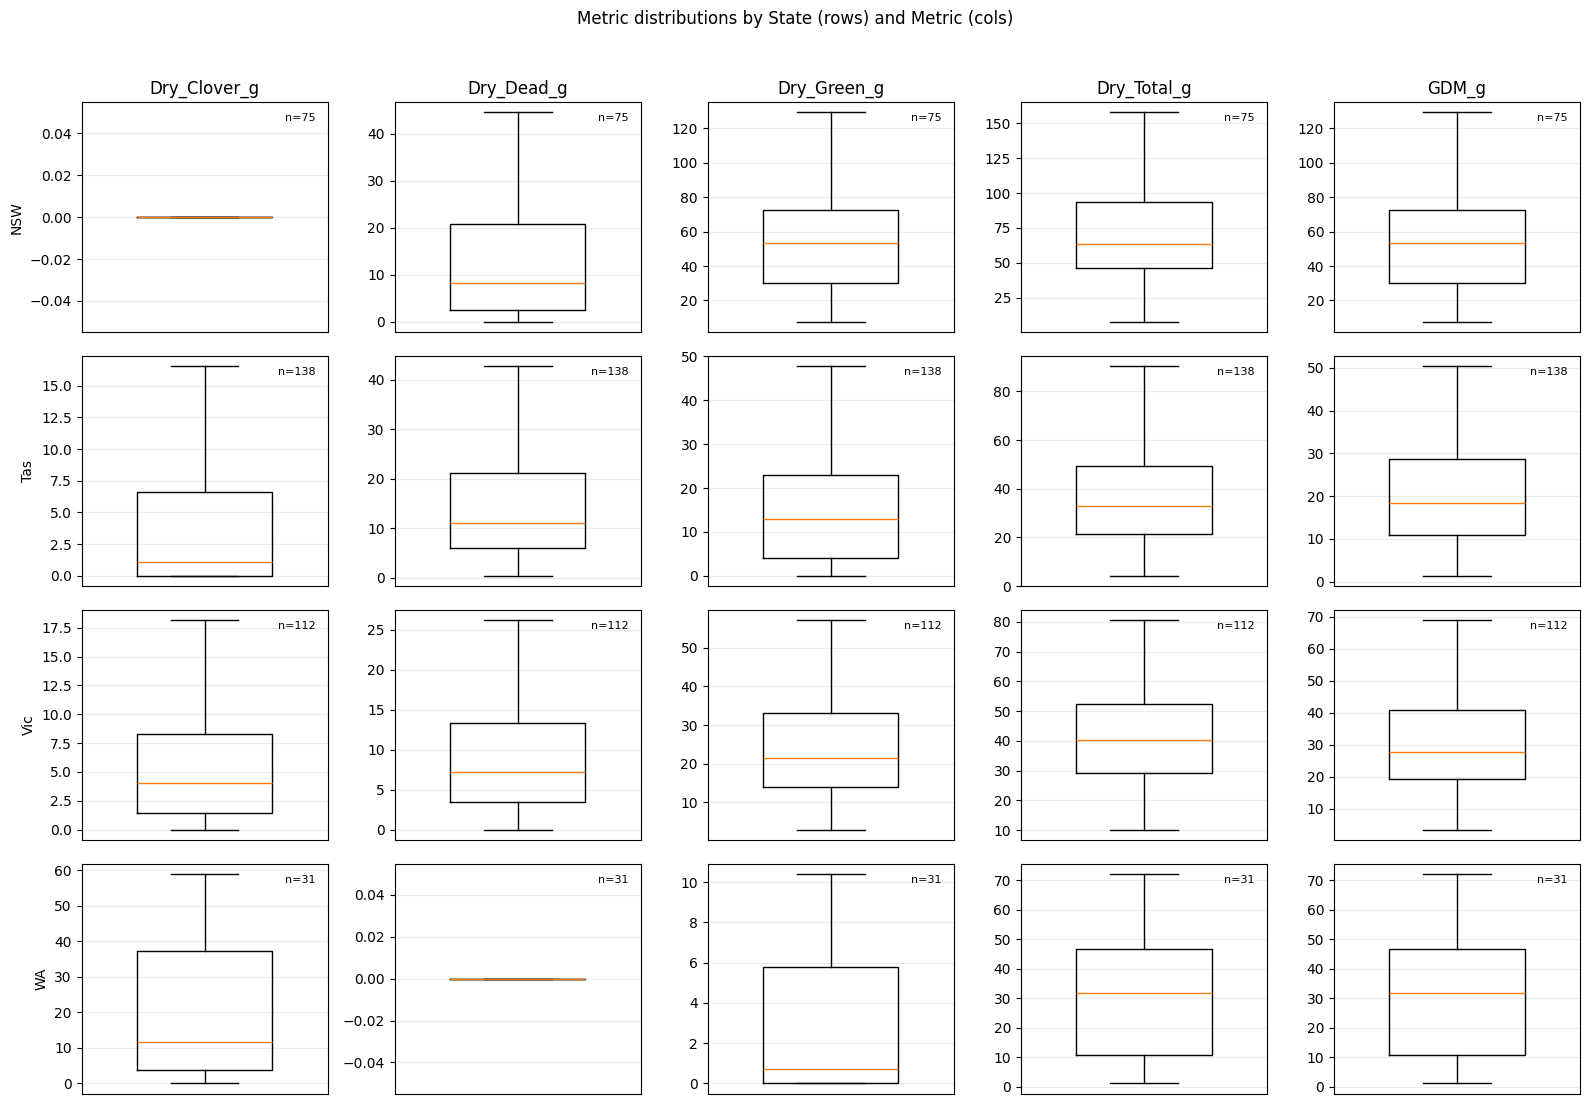

In [19]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 你给的
metric_cols = ['Dry_Clover_g', 'Dry_Dead_g', 'Dry_Green_g', 'Dry_Total_g', 'GDM_g']

df = agg_train_df.copy()

# --- 基础清洗：日期与数值列 ---
if 'Sampling_Date' in df.columns:
    df['Sampling_Date'] = pd.to_datetime(df['Sampling_Date'], errors='coerce')

# 把 metrics / 常用协变量转成数值（避免字符串导致画图报错）
to_numeric_cols = [c for c in (metric_cols + ['Pre_GSHH_NDVI', 'Height_Ave_cm']) if c in df.columns]
for c in to_numeric_cols:
    df[c] = pd.to_numeric(df[c], errors='coerce')

# State 顺序（理论上 4 个）
state_order = list(pd.Series(df['State'].dropna().unique()).sort_values())
print("States:", state_order, " (n_states =", len(state_order), ")")


# ============================================================
# 2) 箱线图网格：State 行，Metric 列（每个格子一个箱线图）
# ============================================================
n_rows = len(state_order)
n_cols = len(metric_cols)

fig, axes = plt.subplots(
    n_rows, n_cols,
    figsize=(3.2 * n_cols, 2.7 * n_rows),
    sharey=False
)

# 处理 n_rows/n_cols 为 1 时 axes 维度退化
if n_rows == 1 and n_cols == 1:
    axes = np.array([[axes]])
elif n_rows == 1:
    axes = np.array([axes])
elif n_cols == 1:
    axes = np.array([[ax] for ax in axes])

for i, st in enumerate(state_order):
    for j, m in enumerate(metric_cols):
        ax = axes[i, j]
        if m not in df.columns:
            ax.set_axis_off()
            continue

        data = df.loc[df['State'] == st, m].dropna().values
        if len(data) == 0:
            ax.set_axis_off()
            continue

        ax.boxplot(
            data,
            widths=0.55,
            showfliers=False
        )

        if i == 0:
            ax.set_title(m)
        if j == 0:
            ax.set_ylabel(str(st))

        ax.set_xticks([])
        ax.grid(True, axis='y', alpha=0.25)
        ax.text(
            0.95, 0.95, f"n={len(data)}",
            transform=ax.transAxes,
            ha="right", va="top",
            fontsize=8
        )

plt.suptitle("Metric distributions by State (rows) and Metric (cols)", y=1.02)
plt.tight_layout()
plt.show()


In [34]:
import pandas as pd
import numpy as np

df = agg_train_df.copy()

# 1) 日期清洗
df["Sampling_Date"] = pd.to_datetime(df["Sampling_Date"], errors="coerce")

# 2) 只保留必要列，并按“图片”去重（避免一张图被5个target重复计数）
base = (
    df.loc[df["Sampling_Date"].notna(), ["sample_id_prefix", "State", "Sampling_Date"]]
      .dropna(subset=["sample_id_prefix", "State"])
      .drop_duplicates(subset=["sample_id_prefix"])  # 一图一票
)

# 3) 取“月份”粒度（按月）
base["Date"] = base["Sampling_Date"].dt.to_period("D").dt.to_timestamp()

# 4) 分组计数：每月×州 的图片数量
cnt = (
    base.groupby(["Date", "State"])["sample_id_prefix"]
        .nunique()
        .reset_index(name="n_images")
        .sort_values(["Date", "State"])
)

print(cnt.head(20))

# 5) 透视表（行=Date，列=State，值=图片数）
pivot = (
    cnt.pivot(index="Date", columns="State", values="n_images")
       .fillna(0)
       .astype(int)
       .sort_index()
)

# 加一列：所有州合计
pivot["ALL"] = pivot.sum(axis=1)

print(pivot.head(12))




         Date State  n_images
0  2015-01-15   NSW        17
1  2015-02-24   NSW        15
2  2015-02-25   NSW         9
3  2015-04-01   NSW        10
4  2015-05-07   NSW        13
5  2015-05-18   Tas        22
6  2015-05-19   Tas         7
7  2015-06-26   Tas        18
8  2015-06-26   Vic        19
9  2015-06-29   Tas        10
10 2015-06-30   Vic         6
11 2015-07-01   Tas        10
12 2015-07-01   Vic         9
13 2015-07-02   Vic        10
14 2015-07-08    WA        12
15 2015-08-14   Vic        18
16 2015-08-18   Vic        10
17 2015-08-19   Vic         1
18 2015-08-21    WA         7
19 2015-09-01    WA        12
State       NSW  Tas  Vic  WA  ALL
Date                              
2015-01-15   17    0    0   0   17
2015-02-24   15    0    0   0   15
2015-02-25    9    0    0   0    9
2015-04-01   10    0    0   0   10
2015-05-07   13    0    0   0   13
2015-05-18    0   22    0   0   22
2015-05-19    0    7    0   0    7
2015-06-26    0   18   19   0   37
2015-06-29    0   10

In [14]:
agg_train_df

,sample_id_prefix,image_path,Sampling_Date,State,Species,Pre_GSHH_NDVI,Height_Ave_cm,Dry_Clover_g,Dry_Dead_g,Dry_Green_g,Dry_Total_g,GDM_g,image
0,ID1011485656,train/ID1011485656.jpg,2015/9/4,Tas,Ryegrass_Clover,0.62,4.6667,0.0000,31.9984,16.2751,48.2735,16.2750,<PIL.Image.Image image mode=RGB size=2000x1000...
1,ID1012260530,train/ID1012260530.jpg,2015/4/1,NSW,Lucerne,0.55,16.0000,0.0000,0.0000,7.6000,7.6000,7.6000,<PIL.Image.Image image mode=RGB size=2000x1000...
2,ID1025234388,train/ID1025234388.jpg,2015/9/1,WA,SubcloverDalkeith,0.38,1.0000,6.0500,0.0000,0.0000,6.0500,6.0500,<PIL.Image.Image image mode=RGB size=2000x1000...
3,ID1028611175,train/ID1028611175.jpg,2015/5/18,Tas,Ryegrass,0.66,5.0000,0.0000,30.9703,24.2376,55.2079,24.2376,<PIL.Image.Image image mode=RGB size=2000x1000...
4,ID1035947949,train/ID1035947949.jpg,2015/9/11,Tas,Ryegrass,0.54,3.5000,0.4343,23.2239,10.5261,34.1844,10.9605,<PIL.Image.Image image mode=RGB size=2000x1000...
...,...,...,...,...,...,...,...,...,...,...,...,...,...
352,ID975115267,train/ID975115267.jpg,2015/7/8,WA,Clover,0.73,3.0000,40.0300,0.0000,0.8000,40.8300,40.8300,<PIL.Image.Image image mode=RGB size=2000x1000...
353,ID978026131,train/ID978026131.jpg,2015/9/4,Tas,Clover,0.83,3.1667,24.6445,4.1948,12.0601,40.8994,36.7046,<PIL.Image.Image image mode=RGB size=2000x1000...
354,ID980538882,train/ID980538882.jpg,2015/2/24,NSW,Phalaris,0.69,29.0000,0.0000,1.1457,91.6543,92.8000,91.6543,<PIL.Image.Image image mode=RGB size=2000x1000...
355,ID980878870,train/ID980878870.jpg,2015/7/8,WA,Clover,0.74,2.0000,32.3575,0.0000,2.0325,34.3900,34.3900,<PIL.Image.Image image mode=RGB size=2000x1000...


In [16]:
import pandas as pd
import numpy as np

df = agg_train_df.copy()

# 1) 日期清洗
df["Sampling_Date"] = pd.to_datetime(df["Sampling_Date"], errors="coerce")

# 2) 只保留必要列，并按“图片”去重（避免一张图被5个target重复计数）
base = (
    df.loc[df["Sampling_Date"].notna(), ["sample_id_prefix", "State", "Sampling_Date"]]
      .dropna(subset=["sample_id_prefix", "State"])
      .drop_duplicates(subset=["sample_id_prefix"])  # 一图一票
)

# 3) 取“月份”粒度（按月）
base["Month"] = base["Sampling_Date"].dt.to_period("M").dt.to_timestamp()

# 4) 分组计数：每月×州 的图片数量
cnt = (
    base.groupby(["Month", "State"])["sample_id_prefix"]
        .nunique()
        .reset_index(name="n_images")
        .sort_values(["Month", "State"])
)

print(cnt.head(20))

# 5) 透视表（行=Month，列=State，值=图片数）
pivot = (
    cnt.pivot(index="Month", columns="State", values="n_images")
       .fillna(0)
       .astype(int)
       .sort_index()
)

# 加一列：所有州合计
pivot["ALL"] = pivot.sum(axis=1)

print(pivot.head(12))




        Month State  n_images
0  2015-01-01   NSW        17
1  2015-02-01   NSW        24
2  2015-04-01   NSW        10
3  2015-05-01   NSW        13
4  2015-05-01   Tas        29
5  2015-06-01   Tas        28
6  2015-06-01   Vic        25
7  2015-07-01   Tas        10
8  2015-07-01   Vic        19
9  2015-07-01    WA        12
10 2015-08-01   Vic        29
11 2015-08-01    WA         7
12 2015-09-01   Tas        34
13 2015-09-01   Vic        21
14 2015-09-01    WA        12
15 2015-10-01   NSW        11
16 2015-10-01   Vic        18
17 2015-11-01   Tas        37
State       NSW  Tas  Vic  WA  ALL
Month                             
2015-01-01   17    0    0   0   17
2015-02-01   24    0    0   0   24
2015-04-01   10    0    0   0   10
2015-05-01   13   29    0   0   42
2015-06-01    0   28   25   0   53
2015-07-01    0   10   19  12   41
2015-08-01    0    0   29   7   36
2015-09-01    0   34   21  12   67
2015-10-01   11    0   18   0   29
2015-11-01    0   37    0   0   37


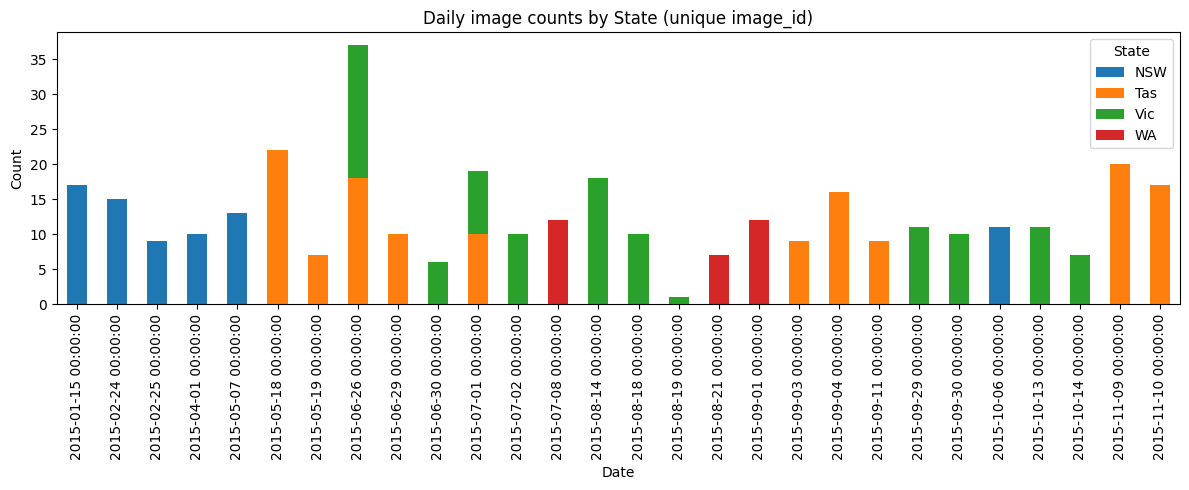

In [35]:
import matplotlib.pyplot as plt

ax = pivot.drop(columns=["ALL"]).plot(kind="bar", stacked=True, figsize=(12,5))
ax.set_title("Daily image counts by State (unique image_id)")
ax.set_xlabel("Date")
ax.set_ylabel("Count")
plt.tight_layout()
plt.show()


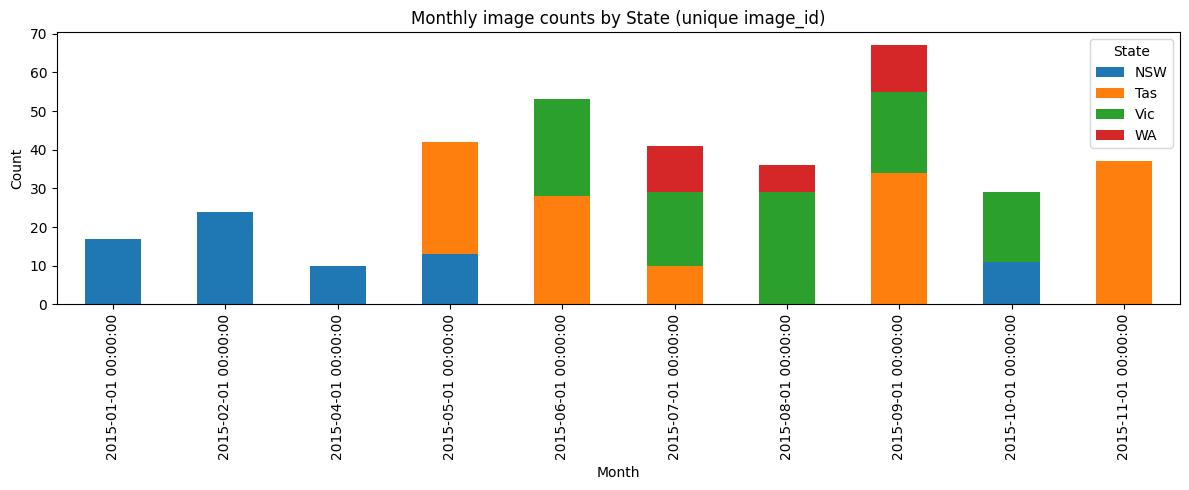

In [17]:
import matplotlib.pyplot as plt

ax = pivot.drop(columns=["ALL"]).plot(kind="bar", stacked=True, figsize=(12,5))
ax.set_title("Monthly image counts by State (unique image_id)")
ax.set_xlabel("Month")
ax.set_ylabel("Count")
plt.tight_layout()
plt.show()


In [26]:
import pandas as pd
import numpy as np

df = agg_train_df.copy()

# 1) 日期清洗
df["Sampling_Date"] = pd.to_datetime(df["Sampling_Date"], errors="coerce")

# 2) 一图一票：按 sample_id_prefix 去重（避免 5 个 target 重复计数）
base = (
    df.loc[df["Sampling_Date"].notna(), ["sample_id_prefix", "State", "Sampling_Date"]]
      .dropna(subset=["sample_id_prefix", "State"])
      .drop_duplicates(subset=["sample_id_prefix"])
)

# 3) 定义澳洲四季 + season_year（12月归到下一年夏季）
def season_au(month: int) -> str:
    if month in (12, 1, 2):
        return "summer"
    elif month in (3, 4, 5):
        return "autumn"
    elif month in (6, 7, 8):
        return "winter"
    else:
        return "spring"

m = base["Sampling_Date"].dt.month
y = base["Sampling_Date"].dt.year

base["Season"] = m.map(season_au)
base["SeasonYear"] = np.where(m == 12, y + 1, y)  # 12月 -> 下一年夏季

# 4) 统计：每(SeasonYear, Season) × State 的 unique sample_id_prefix 数
cnt = (
    base.groupby(["SeasonYear", "Season", "State"])["sample_id_prefix"]
        .nunique()
        .reset_index(name="n_images")
)

# 5) 做成透视表：行=年-季节，列=State，值=图片数
#    固定季节顺序：春夏秋冬（你也可以改）
season_order = ["spring", "summer", "autumn", "winter"]
cnt["Season"] = pd.Categorical(cnt["Season"], categories=season_order, ordered=True)

pivot = (
    cnt.pivot_table(index=["SeasonYear", "Season"], columns="State", values="n_images", fill_value=0)
       .astype(int)
       .sort_index()
)

# 所有州合计
pivot["ALL"] = pivot.sum(axis=1)

print(pivot.head(20))



State              NSW  Tas  Vic  WA  ALL
SeasonYear Season                        
2015       spring   11   71   39  12  133
           summer   41    0    0   0   41
           autumn   23   29    0   0   52
           winter    0   38   73  19  130


C:\Users\Liuluotu\AppData\Local\Temp\ipykernel_61928\9762997.py:46: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  cnt.pivot_table(index=["SeasonYear", "Season"], columns="State", values="n_images", fill_value=0)


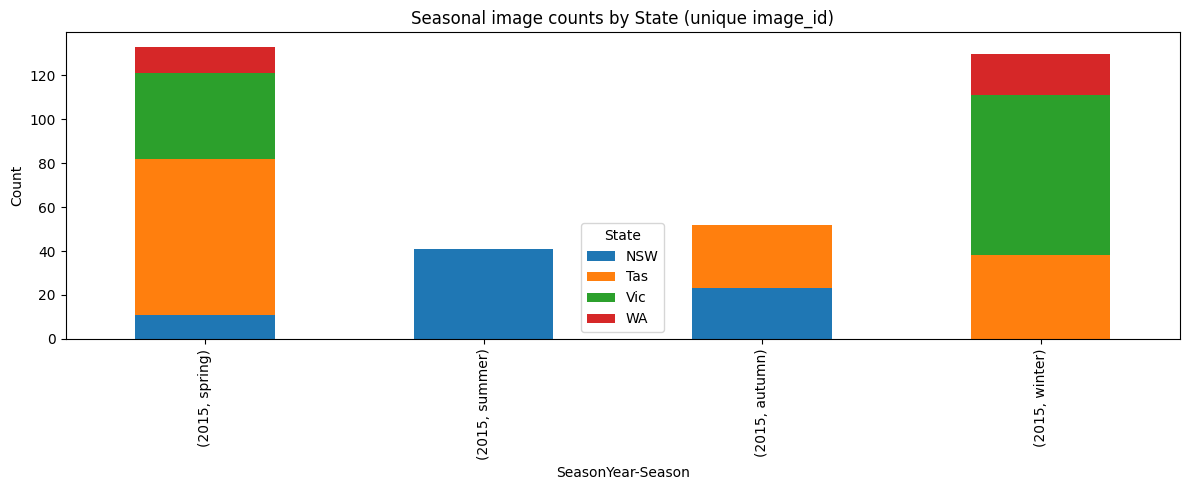

In [27]:
import matplotlib.pyplot as plt

ax = pivot.drop(columns=["ALL"]).plot(kind="bar", stacked=True, figsize=(12,5))
ax.set_title("Seasonal image counts by State (unique image_id)")
ax.set_xlabel("SeasonYear-Season")
ax.set_ylabel("Count")
plt.tight_layout()
plt.show()
